# Data analysis

## Key conclusions 

1. **Data size.** Train has 2,662 rows and 12 specialties. 

2. **Data format.** The raw files have stray `"` characters and records cut by a spreadsheet, so a normal `pd.read_csv` loses rows. There are 3 rows that due to `"` are split in the transcription. There are also 7 rows (lines 161, 714, 947, 1088, 2089, 2329 and 2394)that are incomplete an only have the label and part of the description (we can use them if necessary). Section 1 contains the cleaning code.

3. **The classes are very unbalanced.** Surgery is 33.4% (890 rows) of the data and Dermatology only 0.9% (25 rows). Always answering "Surgery" already gives 33.4% accuracy. Data augmentation is more needed for the small classes.

4. **`keywords` contains the answer.** When it exists (83% of train rows, 80% of test rows), its first item is the specialty name. About 17% of train and 20% of test rows have no keywords, and that is where the models have to understand the clinical text. We must decide if we use this field, and report results with and without it.

5. **The same notes often appears under several specialties.** 40% of distinct notes (732 of 1,836) carry more than one label. So we must use group-aware splits (the same note never in both train and validation), otherwise scores are inflated. In the test file, 61% of transcriptions also appear in train.

6. **Transcription are long.** The median is 387 words and about 53% are probably longer than 512 tokens, so transformers will truncate them. The short fields (`description`, `sample_name`) reach about 50% accuracy alone.


---
## 1. Loading and cleaning the raw files
The raw files contain stray `"` characters and records cut by a spreadsheet, so a normal CSV reader loses rows. This cell reads them line by line instead.

In [ ]:
import os, re, collections, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import entropy, ks_2samp


SPECIALTIES = ['Cardiovascular-Pulmonary','Dermatology','Gastroenterology','General Medicine','Neurology','Neurosurgery',
               'Obstetrics-Gynecology','Ophthalmology','Orthopedic','Psychiatry-Psychology','Radiology','Surgery']
SHORT = dict(zip(SPECIALTIES, ['Cardio-Pulm','Dermatology','Gastro','Gen. Med.','Neurology','Neurosurg.','Ob-Gyn','Ophthalmo.','Orthopedic','Psychiatry','Radiology','Surgery']))
COLS = ['description','sample_name','transcription','keywords']
RECORD = re.compile(r'^(' + '|'.join(map(re.escape, SPECIALTIES)) + r');')

def read_lines(name):
    ls = open(os.path.join(name), encoding='utf-8').read().split('\n')
    return ls[:-1] if ls and ls[-1] == '' else ls

def load_train():
    records = []
    for i, ln in enumerate(read_lines('train.csv')[1:], start=2):
        if RECORD.match(ln): records.append({'line': i, 'raw': ln, 'tail': ''})
        else: records[-1]['tail'] += ln.replace('"', '').rstrip(';')      # orphan line = continuation of a cut record
    rows, dropped = [], 0
    for r in records:
        s = r['raw'].replace('"', '').split(';')                          # drop quotes, split on ';'
        while len(s) > 5 and s[-1] == '': s.pop()                          # padding left by the spreadsheet
        if len(s) < 4: dropped += 1; continue                              # label + description only: unusable
        if len(s) == 4: s.append('')
        if r['tail']: s[3] = s[3].rstrip(';') + r['tail']
        rows.append(s)
    df = pd.DataFrame(rows, columns=['medical_specialty'] + COLS).apply(lambda c: c.str.strip()).replace('', pd.NA)
    print(f'train: {len(records)} record lines -> {len(df)} rows kept ({dropped} incomplete rows dropped)')
    return df

def load_test():
    rows = [ln.replace('"', '').split(';') for ln in read_lines('test_no_labels.csv')]   # NO header in this file
    assert all(len(r) == 4 for r in rows)
    return pd.DataFrame(rows, columns=COLS).apply(lambda c: c.str.strip()).replace('', pd.NA)

tr, te = load_train(), load_test()
print('\nMissing values (%):'); print(pd.DataFrame({'train': tr[COLS].isna().mean()*100, 'test': te[COLS].isna().mean()*100}).round(1).T)
#tr.head(3)

train: 2669 record lines -> 2662 rows kept (7 incomplete rows dropped)

Missing values (%):
       description  sample_name  transcription  keywords
train          0.0          0.0            0.9      16.6
test           0.0          0.0            0.5      19.6


---
## 2. Class distribution

                            n     %
medical_specialty                  
Surgery                   890  33.4
Cardiovascular-Pulmonary  308  11.6
Orthopedic                300  11.3
Radiology                 222   8.3
General Medicine          211   7.9
Gastroenterology          195   7.3
Neurology                 184   6.9
Obstetrics-Gynecology     135   5.1
Neurosurgery               78   2.9
Ophthalmology              73   2.7
Psychiatry-Psychology      41   1.5
Dermatology                25   0.9

largest/smallest class: 36x | always predicting 'Surgery' gives accuracy 0.334


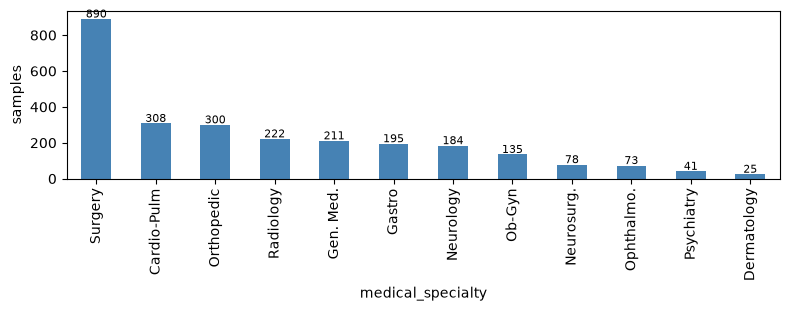

In [2]:
vc = tr.medical_specialty.value_counts()
print(pd.DataFrame({'n': vc, '%': (vc/len(tr)*100).round(1)}))
print(f"\nlargest/smallest class: {vc.max()/vc.min():.0f}x | always predicting '{vc.index[0]}' gives accuracy {vc.max()/len(tr):.3f}")
fig, ax = plt.subplots(figsize=(8,3.2)); vc.rename(SHORT).plot.bar(ax=ax, color='steelblue')
for i, v in enumerate(vc.values): ax.text(i, v+8, v, ha='center', fontsize=8)
ax.set_ylabel('samples'); plt.tight_layout(); plt.show()

---
## 3. Text length

      w_description  w_sample_name  w_transcription  w_keywords
mean           19.0            4.0            453.0        23.0
50%            16.0            4.0            387.0        19.0
95%            43.0            6.0           1026.0        87.0
max            76.0            8.0           2454.0       118.0
~82% of transcriptions are probably longer than 256 tokens (rough proxy: words x 1.4)
~53% of transcriptions are probably longer than 512 tokens (rough proxy: words x 1.4)


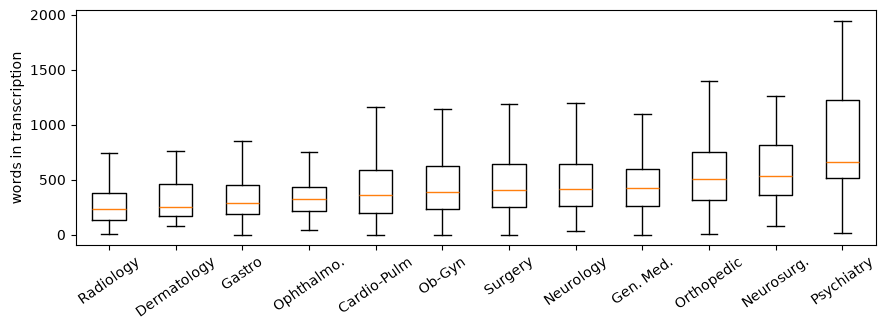

In [3]:
for c in COLS: tr['w_'+c] = tr[c].fillna('').str.split().str.len(); te['w_'+c] = te[c].fillna('').str.split().str.len()
print(tr[['w_description','w_sample_name','w_transcription','w_keywords']].describe(percentiles=[.5,.95]).round(0).loc[['mean','50%','95%','max']])
for lim in (256, 512): print(f"~{(tr.w_transcription*1.4 > lim).mean()*100:.0f}% of transcriptions are probably longer than {lim} tokens (rough proxy: words x 1.4)")
order = tr.groupby('medical_specialty').w_transcription.median().sort_values().index
fig, ax = plt.subplots(figsize=(9,3.4))
ax.boxplot([tr.loc[tr.medical_specialty==c,'w_transcription'].clip(upper=2500) for c in order], tick_labels=[SHORT[c] for c in order], showfliers=False)
ax.set_ylabel('words in transcription'); plt.xticks(rotation=35); plt.tight_layout(); plt.show()

---
## 4. The `keywords` shortcut and how informative each field is

In [4]:
k = tr.dropna(subset=['keywords']).copy(); k['first'] = k.keywords.str.split(',').str[0].str.strip().str.lower()
print('Most common first keyword:'); print(k['first'].value_counts().head(12).to_string())
rule = k.groupby('first').medical_specialty.agg(lambda s: s.value_counts().index[0])
print(f"\nRule 'first keyword -> its most common label' on rows that have keywords: accuracy {(rule.reindex(k['first']).values == k.medical_specialty.values).mean():.3f}")
print(f"Rows without keywords: train {tr.keywords.isna().mean()*100:.1f}%, test {te.keywords.isna().mean()*100:.1f}%")

Most common first keyword:
first
surgery                       830
orthopedic                    252
cardiovascular / pulmonary    230
radiology                     203
gastroenterology              166
neurology                     134
general medicine              122
obstetrics / gynecology       112
ophthalmology                  70
neurosurgery                   66
dermatology                    20
psychiatry / psychology        14

Rule 'first keyword -> its most common label' on rows that have keywords: accuracy 1.000
Rows without keywords: train 16.6%, test 19.6%


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score

y = tr.medical_specialty.values
groups = pd.factorize(tr.transcription.fillna(pd.Series('missing_' + tr.index.astype(str), index=tr.index)))[0]   # same note -> same fold
folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(tr, y, groups))
text = lambda cols: tr[cols].fillna('').agg(' . '.join, axis=1)

configs = {'sample_name': ['sample_name'], 'description': ['description'], 'keywords': ['keywords'], 'transcription': ['transcription'],
           'all except keywords': ['description','sample_name','transcription'], 'all four': COLS}
res, preds = [], {}
for name, cols in configs.items():
    p = make_pipeline(TfidfVectorizer(sublinear_tf=True, min_df=2), LogisticRegression(max_iter=2000, class_weight='balanced'))
    preds[name] = cross_val_predict(p, text(cols), y, cv=folds)
    res.append((name, accuracy_score(y, preds[name]), f1_score(y, preds[name], average='macro')))
print(pd.DataFrame(res, columns=['input','accuracy','macro-F1']).round(3).to_string(index=False))
has_kw = tr.keywords.notna().values
for n in ['all except keywords', 'all four']:
    print(f"{n}: accuracy WITH keywords {accuracy_score(y[has_kw], preds[n][has_kw]):.3f} | WITHOUT keywords {accuracy_score(y[~has_kw], preds[n][~has_kw]):.3f}")

              input  accuracy  macro-F1
        sample_name     0.505     0.505
        description     0.504     0.508
           keywords     0.761     0.755
      transcription     0.560     0.595
all except keywords     0.568     0.605
           all four     0.629     0.663
all except keywords: accuracy WITH keywords 0.565 | WITHOUT keywords 0.582
all four: accuracy WITH keywords 0.640 | WITHOUT keywords 0.576


---
## 5. The same note filed under several specialties

In [6]:
d = tr.dropna(subset=['transcription'])
labels_per_note = d.groupby('transcription').medical_specialty.agg(lambda s: tuple(sorted(set(s))))
conflict = labels_per_note[labels_per_note.map(len) > 1]
print(f'{len(d)} rows with a transcription = {len(labels_per_note)} distinct notes; {len(conflict)} notes ({len(conflict)/len(labels_per_note)*100:.0f}%) have more than one label')
print('Most common label sets:'); [print(f'  {v:4d}  {" / ".join(s)}') for s, v in collections.Counter(conflict).most_common(6)]
in_train = te.transcription.dropna().isin(set(d.transcription))
amb = te.transcription.map(lambda t: len(labels_per_note.get(t, ())) if isinstance(t, str) else 0)
print(f"\nTest transcriptions that also appear in train: {in_train.sum()} of {te.transcription.notna().sum()} ({in_train.mean()*100:.0f}%)")
print(f"  with conflicting labels in train: {(amb>1).sum()} | of those, without keywords to break the tie: {((amb>1)&te.keywords.isna()).sum()}")
ex = conflict.index[0]; print('\nExample note filed under', conflict.iloc[0]); print(tr[tr.transcription==ex][['medical_specialty','sample_name','keywords']].to_string())

2638 rows with a transcription = 1836 distinct notes; 732 notes (40%) have more than one label
Most common label sets:
   123  Cardiovascular-Pulmonary / Surgery
   122  Orthopedic / Surgery
    97  Gastroenterology / Surgery
    67  Obstetrics-Gynecology / Surgery
    44  Cardiovascular-Pulmonary / Radiology
    42  Ophthalmology / Surgery

Test transcriptions that also appear in train: 240 of 396 (61%)
  with conflicting labels in train: 29 | of those, without keywords to break the tie: 8

Example note filed under ('Obstetrics-Gynecology', 'Surgery')
          medical_specialty                         sample_name                                                                                                                                                                                                                                                                                                                                                                               keywords
10